# Exploratory Data Analysis of "Credit-Fearful" Households in the Survey of Consumer Finances (SCF 2019) Using Pandas, Matplotlib, and Seaborn

## Latihan dengan data dummy (5 baris)

1. Membuat DataFrame kecil toy_df (household_id, income, debt, age_group, credit_fear). .shape menampilkan ukuran (5, 5), .head() menampilkan baris awal.

In [1]:
import pandas as pd

# Create a small toy DataFrame to demonstrate inspection methods
toy_data = {
    "household_id": [1, 2, 3, 4, 5],
    "income": [50000, 75000, 120000, 45000, 90000],
    "debt": [10000, 25000, 50000, 5000, 30000],
    "age_group": [2, 3, 4, 1, 3],
    "credit_fear": [1, 0, 0, 1, 0],
}
toy_df = pd.DataFrame(toy_data)

# Display the shape (rows, columns)
print("Shape:", toy_df.shape)

# Display the first few rows
toy_df.head()

Shape: (5, 5)


,household_id,income,debt,age_group,credit_fear
0,1,50000,10000,2,1
1,2,75000,25000,3,0
2,3,120000,50000,4,0
3,4,45000,5000,1,1
4,5,90000,30000,3,0


2. .dtypes mengecek tipe data tiap kolom (semuanya int64).

In [2]:
# Check data types for each column
print(toy_df.dtypes)

household_id    int64
income          int64
debt            int64
age_group       int64
credit_fear     int64
dtype: object


3. .describe() menghitung statistik ringkas: mean, std, min, kuartil, max.

In [3]:
# Get summary statistics for numeric columns
toy_df.describe()

,household_id,income,debt,age_group,credit_fear
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,3.000000,76000.000000,24000.000000,2.600000,0.400000
std,1.581139,30700.162866,17818.529681,1.140175,0.547723
min,1.000000,45000.000000,5000.000000,1.000000,0.000000
25%,2.000000,50000.000000,10000.000000,2.000000,0.000000
50%,3.000000,75000.000000,25000.000000,3.000000,0.000000
75%,4.000000,90000.000000,30000.000000,3.000000,1.000000
max,5.000000,120000.000000,50000.000000,4.000000,1.000000


4. Membuat boolean mask credit_fear == 1, yaitu True/False per baris.

In [4]:
# Create a boolean mask: True where credit_fear equals 1
mask = toy_df["credit_fear"] == 1
print("Boolean mask:")
print(mask)

Boolean mask:
0     True
1    False
2    False
3     True
4    False
Name: credit_fear, dtype: bool


5. Menerapkan mask untuk memfilter baris. Dari 5 baris tersisa 2.

In [5]:
# Apply the mask to filter rows
subset = toy_df[mask]
print(f"Original rows: {len(toy_df)}, Subset rows: {len(subset)}")
subset

Original rows: 5, Subset rows: 2


,household_id,income,debt,age_group,credit_fear
0,1,50000,10000,2,1
3,4,45000,5000,1,1


6. .replace(age_dict) mengubah kode usia (1–4) menjadi label (“Under 35”, “35-44”, dst.).

In [6]:
# Dictionary mapping numeric codes to labels
age_dict = {1: "Under 35", 2: "35-44", 3: "45-54", 4: "55-64"}

# Replace codes with labels
age_labels = toy_df["age_group"].replace(age_dict)
print("Original codes:")
print(toy_df["age_group"].values)
print("\nAfter replacement:")
print(age_labels.values)

Original codes:
[2 3 4 1 3]

After replacement:
['35-44' '45-54' '55-64' 'Under 35' '45-54']


7. .unique() membandingkan nilai unik sebelum dan sesudah penggantian label.

In [7]:
# Check unique values before and after replacement
print("Unique codes:", toy_df["age_group"].unique())
print("Unique labels:", age_labels.unique())

Unique codes: [2 3 4 1]
Unique labels: ['35-44' '45-54' '55-64' 'Under 35']


8. .value_counts() menghitung frekuensi tiap kelompok usia.

In [8]:
# Count occurrences of each age group label
age_labels.value_counts()

age_group
45-54       2
35-44       1
55-64       1
Under 35    1
Name: count, dtype: int64

9. .value_counts(normalize=True) menghasilkan proporsi (total = 1.0).

In [9]:
# Normalized frequencies sum to 1.0
age_labels.value_counts(normalize=True)

age_group
45-54       0.4
35-44       0.2
55-64       0.2
Under 35    0.2
Name: proportion, dtype: float64

10. groupby("credit_fear")["income"].mean() menghitung rata-rata income per grup (0: 95.000, 1: 47.500).

In [10]:
# Group by credit_fear and compute mean income for each group
toy_df.groupby("credit_fear")["income"].mean()

credit_fear
0    95000.0
1    47500.0
Name: income, dtype: float64

11. groupby digabung value_counts(normalize=True) untuk proporsi usia di tiap grup credit_fear.

In [11]:
# Combine groupby with value_counts for cross-tabulation
# Count age groups within each credit_fear category
(
    toy_df["age_group"]
    .replace(age_dict)
    .groupby(toy_df["credit_fear"])
    .value_counts(normalize=True)
)

credit_fear  age_group
0            45-54        0.666667
             55-64        0.333333
1            35-44        0.500000
             Under 35     0.500000
Name: proportion, dtype: float64

12. Bar chart distribusi kelompok usia memakai Matplotlib.

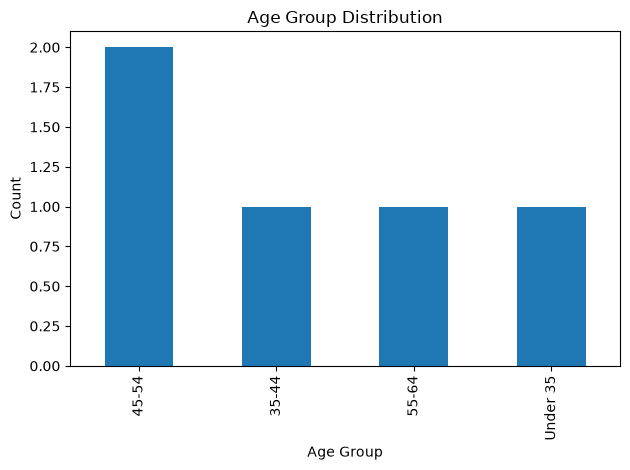

In [12]:
import matplotlib.pyplot as plt

# Bar chart from value counts
counts = age_labels.value_counts()
counts.plot(kind="bar", xlabel="Age Group", ylabel="Count",
            title="Age Group Distribution")
plt.tight_layout();

13. Histogram income (5 bin).

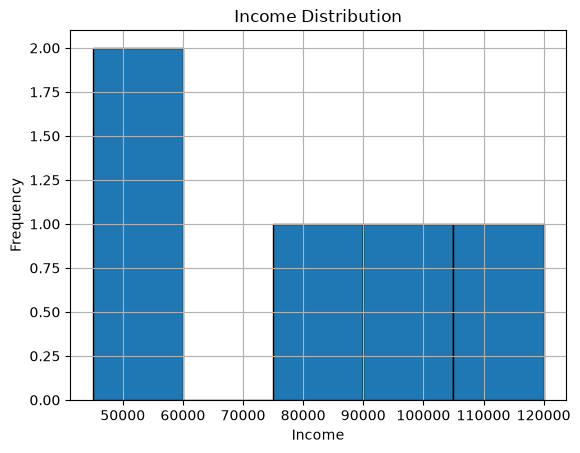

In [13]:
# Histogram of a numeric column
toy_df["income"].hist(bins=5, edgecolor="black")
plt.xlabel("Income")
plt.ylabel("Frequency")
plt.title("Income Distribution");

14. Scatter plot income vs debt.

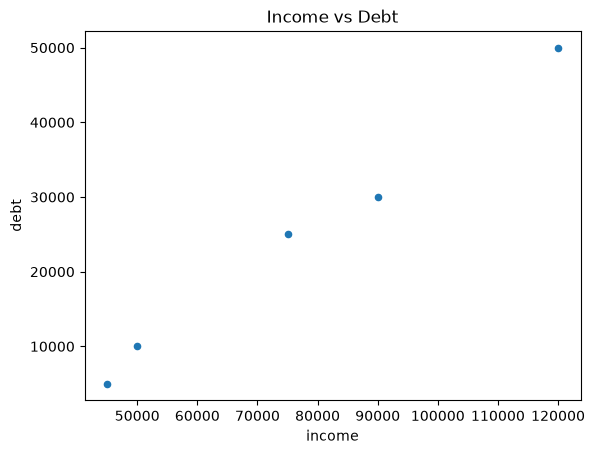

In [14]:
# Scatter plot to visualize relationships
toy_df.plot.scatter(x="income", y="debt")
plt.title("Income vs Debt");

15. Menyiapkan DataFrame tidy df_freq (credit_fear, age_group, frequency) untuk Seaborn.

In [15]:
import seaborn as sns

# Prepare data for seaborn: need a tidy DataFrame
# Compute frequencies by credit_fear and age_group
df_freq = (
    toy_df["age_group"]
    .replace(age_dict)
    .groupby(toy_df["credit_fear"])
    .value_counts(normalize=True)
    .rename("frequency")
    .reset_index()
)
df_freq

,credit_fear,age_group,frequency
0,0,45-54,0.666667
1,0,55-64,0.333333
2,1,35-44,0.500000
3,1,Under 35,0.500000


16. sns.barplot membuat bar chart berdampingan antar grup.

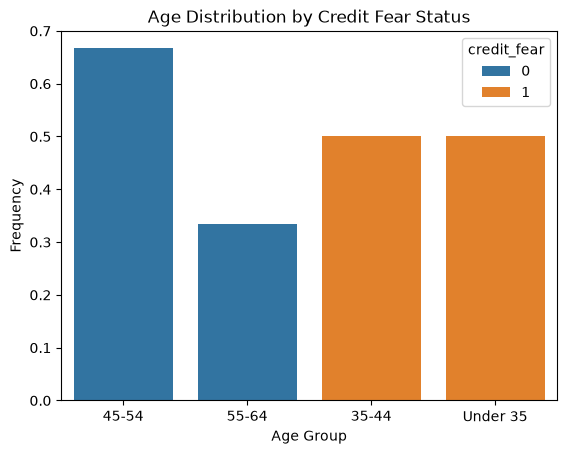

In [16]:
# Side-by-side bar chart comparing groups
sns.barplot(x="age_group", y="frequency", hue="credit_fear", data=df_freq)
plt.xlabel("Age Group")
plt.ylabel("Frequency")
plt.title("Age Distribution by Credit Fear Status");

17. .corr() menghitung korelasi income–debt (0,996).

In [17]:
# Compute correlation between two columns
corr_value = toy_df["income"].corr(toy_df["debt"])
print(f"Correlation between income and debt: {corr_value:.3f}")

Correlation between income and debt: 0.996


18. Matriks korelasi income dan debt.

In [18]:
# Compute correlation matrix for all numeric columns
corr_matrix = toy_df[["income", "debt"]].corr()
corr_matrix

,income,debt
income,1.000000,0.996286
debt,0.996286,1.000000


19. .style.background_gradient mewarnai matriks korelasi (heatmap sederhana).

In [19]:
# Style the correlation matrix with color gradients
corr_matrix.style.background_gradient(axis=None, cmap="coolwarm")

,income,debt
income,1.000000,0.996286
debt,0.996286,1.000000


## Proyek utama dengan data SCF 2019

1. Mengimpor matplotlib, pandas, seaborn.

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

2. Memuat SCFP2019.csv.gz. Ukuran data 28.885 baris × 351 kolom.

In [21]:
# Load the SCF dataset from compressed CSV
df = pd.read_csv("data/SCFP2019.csv.gz")  # read "data/SCFP2019.csv.gz"
print("df shape:", df.shape)
df.head()

df shape: (28885, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,6119.779308,2,75,6,12,4,2,0,...,5,3,6,3,2,10,6,6,3,3
1,1,12,4712.374912,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
2,1,13,5145.224455,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2
3,1,14,5297.663412,2,75,6,12,4,2,0,...,5,2,6,2,1,10,4,4,2,2
4,1,15,4761.812371,2,75,6,12,4,2,0,...,5,3,6,3,1,10,5,5,2,2


3. 	Membuat mask TURNFEAR == 1 dan subset df_fear (4.623 rumah tangga yang takut kredit).

In [22]:
# Create a mask for credit-fearful households (TURNFEAR == 1)
mask = df["TURNFEAR"] == 1  # condition for TURNFEAR equals 1
df_fear = df[mask]
print("df_fear shape:", df_fear.shape)
df_fear.head()

df_fear shape: (4623, 351)


,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
5,2,21,3790.476607,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
6,2,22,3798.868505,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,3,2,2
7,2,23,3799.468393,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
8,2,24,3788.076005,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2
9,2,25,3793.066589,1,50,3,8,2,1,3,...,1,2,1,2,1,1,4,4,2,2


4. assert untuk memvalidasi jumlah kolom/baris dan bahwa df_fear memang subset.

In [23]:
# Verify dataset dimensions and subset
assert df.shape[1] == 351, (
    f"Expected 351 columns in df, got {df.shape[1]}"
)
assert df.shape[0] > 20000, (
    f"Expected more than 20000 rows in df, got {df.shape[0]}"
)
assert df_fear.shape[0] < df.shape[0], (
    "df_fear should be a subset smaller than df"
)
assert (df_fear["TURNFEAR"] == 1).all(), (
    "All rows in df_fear should have TURNFEAR == 1"
)
print("All checks passed!")

All checks passed!


5. Mengecek nilai unik AGECL. Sel ini tanpa output, jadi sepertinya belum dieksekusi.

In [24]:
# Get unique age group codes to understand the encoding
age_groups = df_fear["AGECL"].unique()  # unique values from df_fear["AGECL"]
print("Age Groups:", age_groups)

Age Groups: [3 5 1 2 4 6]


6. Mengganti kode AGECL dengan label usia memakai agecl_dict.

In [25]:
# Dictionary mapping age codes to labels (from Code Book)
agecl_dict = {
    1: "Under 35",
    2: "35-44",
    3: "45-54",
    4: "55-64",
    5: "65-74",
    6: "75 or Older",
}

# Replace numeric codes with descriptive labels
age_cl = df_fear["AGECL"].replace(agecl_dict)
age_cl.head()

5    45-54
6    45-54
7    45-54
8    45-54
9    45-54
Name: AGECL, dtype: object

7. Bar chart frekuensi kelompok usia untuk kelompok credit fearful.

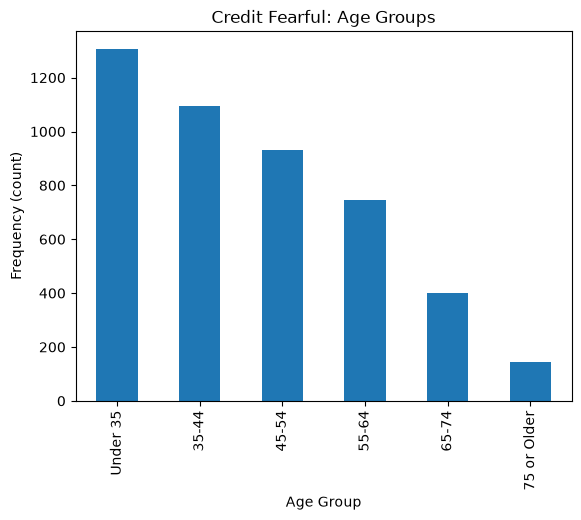

In [26]:
# Create bar chart of age group frequencies
age_cl_value_counts = age_cl.value_counts()  # value_counts of age_cl

# Plot bar chart
age_cl_value_counts.plot(
    kind="bar",
    xlabel="Age Group",
    ylabel="Frequency (count)",
    title="Credit Fearful: Age Groups"
);

8. Histogram AGE (10 bin) untuk melihat sebaran usia lebih detail.

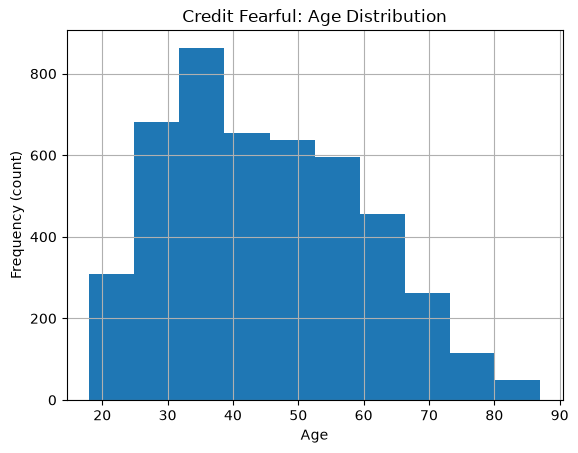

In [27]:
# Create histogram of continuous AGE variable for finer detail
df_fear["AGE"].hist(bins=10)  # histogram of df_fear["AGE"] with 10 bins
plt.xlabel("Age")
plt.ylabel("Frequency (count)")
plt.title("Credit Fearful: Age Distribution");

9. assert untuk memvalidasi hasil pemrosesan usia (6 kelompok, jumlah frekuensi sesuai).

In [28]:
# Verify age group processing
assert len(age_cl.unique()) == 6, (
    f"Expected 6 unique age groups, got {len(age_cl.unique())}"
)
assert age_cl.dtype == object, (
    "age_cl should contain string labels after replacement"
)
assert age_cl_value_counts.sum() == len(df_fear), (
    f"Value counts should sum to {len(df_fear)}, got {age_cl_value_counts.sum()}"
)
print("All checks passed!")

All checks passed!


10. Bar chart horizontal proporsi ras (RACE) pada kelompok credit fearful.

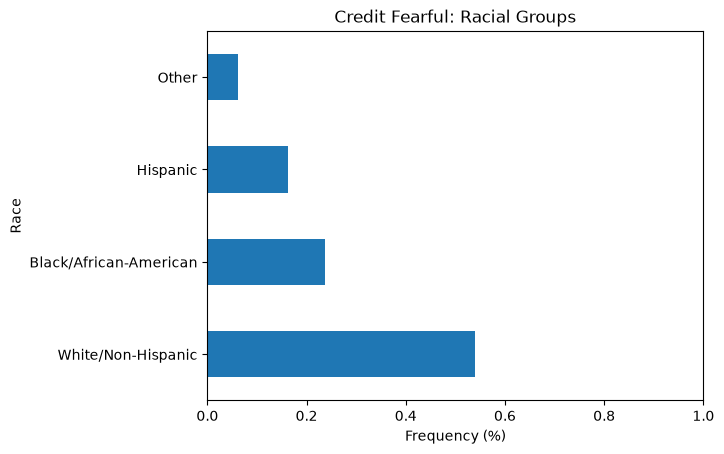

In [29]:
# Dictionary mapping race codes to labels (from Code Book)
# Note: Code 4 does not exist in this dataset
race_dict = {
    1: "White/Non-Hispanic",
    2: "Black/African-American",
    3: "Hispanic",
    5: "Other",
}

# Create normalized bar chart for credit-fearful subset
race = df_fear["RACE"].replace(race_dict)  # replace codes in df_fear["RACE"] using race_dict
race_value_counts = race.value_counts(normalize=True)  # normalized value_counts

# Plot horizontal bar chart
race_value_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("Credit Fearful: Racial Groups");

11. Bar chart yang sama untuk seluruh responden SCF sebagai pembanding.

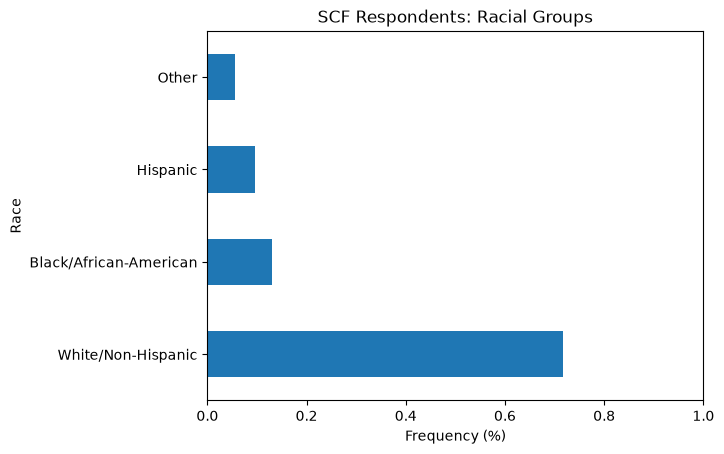

In [30]:
# Compare with full dataset to understand baseline proportions
race_full = df["RACE"].replace(race_dict)  # replace codes in df["RACE"] using race_dict
race_full_counts = race_full.value_counts(normalize=True)  # normalized value_counts

# Plot horizontal bar chart for full dataset
race_full_counts.plot(kind="barh")
plt.xlim((0, 1))
plt.xlabel("Frequency (%)")
plt.ylabel("Race")
plt.title("SCF Respondents: Racial Groups");

12. assert bahwa frekuensi ternormalisasi berjumlah ≈ 1.

In [31]:
# Verify normalized frequencies sum to ~1.0
assert abs(race_value_counts.sum() - 1.0) < 0.01, (
    f"Normalized frequencies should sum to ~1.0, got {race_value_counts.sum()}"
)
assert abs(race_full_counts.sum() - 1.0) < 0.01, (
    f"Full dataset frequencies should sum to ~1.0, got {race_full_counts.sum()}"
)
print("All checks passed!")

All checks passed!


13. Menghitung proporsi kategori pendapatan (INCCAT) per grup TURNFEAR menjadi df_inccat.

In [32]:
# Dictionary mapping income percentile codes to labels
inccat_dict = {
    1: "0-20",
    2: "20-39.9",
    3: "40-59.9",
    4: "60-79.9",
    5: "80-89.9",
    6: "90-100",
}

# Compute normalized frequencies by TURNFEAR group
# Chain: replace -> groupby -> value_counts -> rename -> reset_index
df_inccat = (
    df["INCCAT"]
    .replace(inccat_dict)
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)  # value_counts with normalize=True
    .rename("frequency")  # rename to "frequency"
    .reset_index()  # reset_index
)

df_inccat

,TURNFEAR,INCCAT,frequency
0,0,90-100,0.297296
1,0,60-79.9,0.174841
2,0,40-59.9,0.143146
3,0,0-20,0.140343
4,0,20-39.9,0.135933
5,0,80-89.9,0.108441
6,1,0-20,0.288125
7,1,20-39.9,0.256327
8,1,40-59.9,0.228856
9,1,60-79.9,0.132598


14. Bar chart berdampingan distribusi pendapatan antara fearful dan non-fearful.

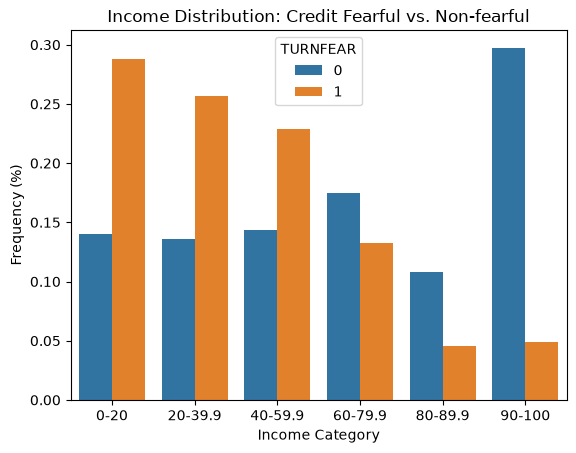

In [33]:
# Create side-by-side bar chart comparing income distributions
sns.barplot(
    x="INCCAT",  # x=..., y=..., hue=...
    y="frequency",  # data=df_inccat
    hue="TURNFEAR",  # order=inccat_dict.values()
    data=df_inccat,
    order=inccat_dict.values(),
)
plt.xlabel("Income Category")
plt.ylabel("Frequency (%)")
plt.title("Income Distribution: Credit Fearful vs. Non-fearful");

15. assert validasi struktur df_inccat (tiap grup berjumlah ≈ 1).

In [34]:
# Verify grouped DataFrame structure
assert "TURNFEAR" in df_inccat.columns, "df_inccat should have TURNFEAR column"
assert "INCCAT" in df_inccat.columns, "df_inccat should have INCCAT column"
assert "frequency" in df_inccat.columns, "df_inccat should have frequency column"
# Check frequencies sum to ~1.0 for each group
for grp in [0, 1]:
    grp_sum = df_inccat[df_inccat["TURNFEAR"] == grp]["frequency"].sum()
    assert abs(grp_sum - 1.0) < 0.01, (
        f"Frequencies for TURNFEAR={grp} should sum to ~1.0, got {grp_sum}"
    )
print("All checks passed!")

All checks passed!


16. Korelasi ASSET vs HOUSES untuk seluruh data (0,52) dan subset fearful (0,583).

In [35]:
# Compute correlation between ASSET and HOUSES for full dataset
asset_house_corr_full = df["ASSET"].corr(df["HOUSES"])  # correlation of df["ASSET"] with df["HOUSES"]
print("SCF: Asset-Houses Correlation:", round(asset_house_corr_full, 3))

SCF: Asset-Houses Correlation: 0.52


In [36]:
# Compute same correlation for credit-fearful subset
asset_house_corr_fear = df_fear["ASSET"].corr(df_fear["HOUSES"])  # correlation for df_fear
print("Credit Fearful: Asset-Houses Correlation:",
      round(asset_house_corr_fear, 3))

Credit Fearful: Asset-Houses Correlation: 0.583


17. Matriks korelasi ASSET, HOUSES, INCOME, DEBT, EDUC untuk seluruh data.

In [37]:
# Define columns for correlation matrix
cols = ["ASSET", "HOUSES", "INCOME", "DEBT", "EDUC"]

# Compute correlation matrix for full dataset
corr_full = df[cols].corr()  # correlation matrix for df[cols]
corr_full.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.519827,0.622429,0.261250,0.116673
HOUSES,0.519827,1.000000,0.247852,0.266661,0.169300
INCOME,0.622429,0.247852,1.000000,0.114646,0.069400
DEBT,0.261250,0.266661,0.114646,1.000000,0.054179
EDUC,0.116673,0.169300,0.069400,0.054179,1.000000


18. Matriks korelasi yang sama untuk subset fearful.

In [38]:
# Compute correlation matrix for credit-fearful subset
corr_fear = df_fear[cols].corr()  # correlation matrix for df_fear[cols]
corr_fear.style.background_gradient(axis=None)

,ASSET,HOUSES,INCOME,DEBT,EDUC
ASSET,1.000000,0.583288,0.722074,0.474658,0.113536
HOUSES,0.583288,1.000000,0.264099,0.962629,0.160348
INCOME,0.722074,0.264099,1.000000,0.172393,0.133170
DEBT,0.474658,0.962629,0.172393,1.000000,0.177386
EDUC,0.113536,0.160348,0.133170,0.177386,1.000000


19. assert bahwa korelasi berada di rentang [-1, 1] dan matriks berukuran 5×5.

In [39]:
# Verify correlation values are in valid range [-1, 1]
assert -1 <= asset_house_corr_full <= 1, (
    f"Correlation should be in [-1, 1], got {asset_house_corr_full}"
)
assert -1 <= asset_house_corr_fear <= 1, (
    f"Correlation should be in [-1, 1], got {asset_house_corr_fear}"
)
# Verify correlation matrix shape
assert corr_full.shape == (5, 5), (
    f"Expected correlation matrix shape (5, 5), got {corr_full.shape}"
)
assert corr_fear.shape == (5, 5), (
    f"Expected correlation matrix shape (5, 5), got {corr_fear.shape}"
)
print("All checks passed!")

All checks passed!


20. Menghitung proporsi tingkat pendidikan (EDUC) per grup TURNFEAR.

In [40]:
# Compute education frequencies by TURNFEAR group
# Note: We keep numeric codes for EDUC (grade levels) for ordering
df_educ = (
    df["EDUC"]
    .groupby(df["TURNFEAR"])
    .value_counts(normalize=True)
    .rename("frequency")
    .reset_index()
)
df_educ.head()

,TURNFEAR,EDUC,frequency
0,0,12,0.257481
1,0,8,0.192029
2,0,13,0.149823
3,0,9,0.129833
4,0,14,0.096117


21. Bar chart berdampingan tingkat pendidikan fearful vs non-fearful.

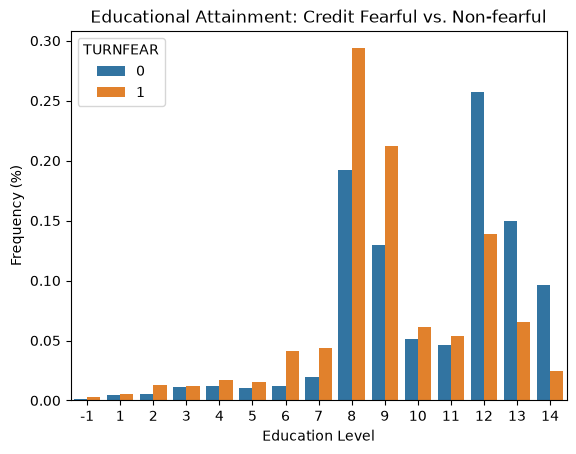

In [41]:
# Create side-by-side bar chart for education
sns.barplot(x="EDUC", y="frequency", hue="TURNFEAR", data=df_educ) # x="EDUC", y="frequency", hue="TURNFEAR", data=df_educ
plt.xlabel("Education Level")
plt.ylabel("Frequency (%)")
plt.title("Educational Attainment: Credit Fearful vs. Non-fearful");

22. Scatter plot DEBT vs ASSET untuk seluruh data dan subset fearful.

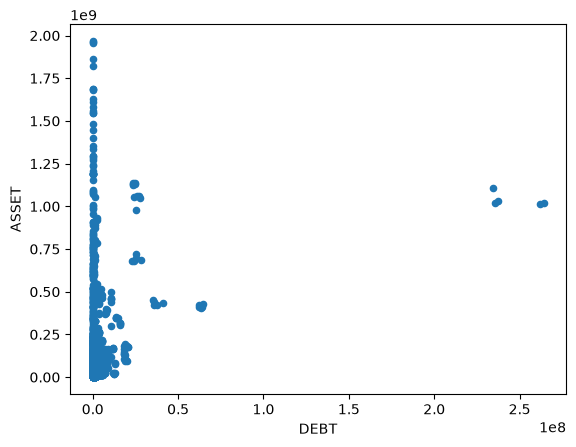

In [42]:
# Create scatter plot of DEBT vs ASSET for full dataset
df.plot.scatter(x="DEBT", y="ASSET"); # x="DEBT", y="ASSET"

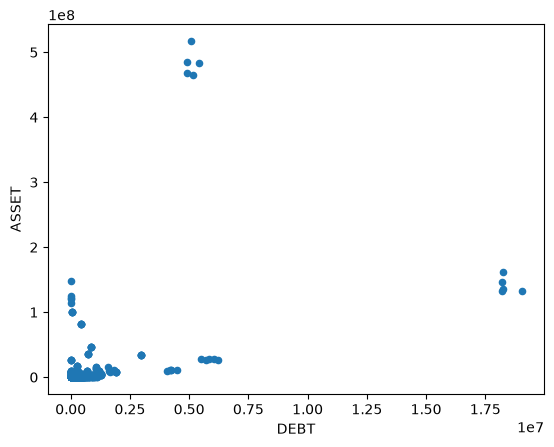

In [43]:
# Create scatter plot of DEBT vs ASSET for credit-fearful subset
df_fear.plot.scatter(x="DEBT", y="ASSET");  # x="DEBT", y="ASSET"

23. Scatter plot DEBT vs HOUSES untuk seluruh data dan subset fearful.

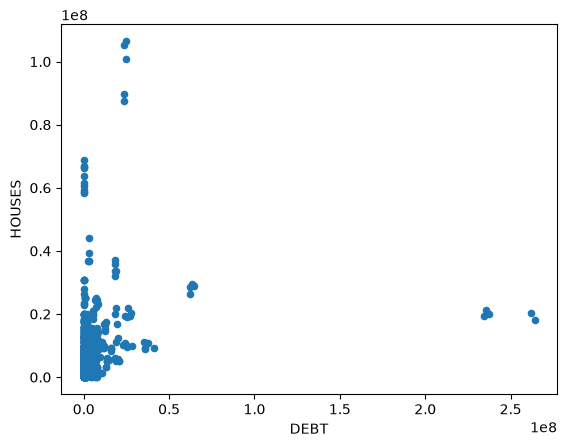

In [44]:
# Create scatter plot of DEBT vs HOUSES for full dataset
df.plot.scatter(x="DEBT", y="HOUSES");  # x="DEBT", y="HOUSES"

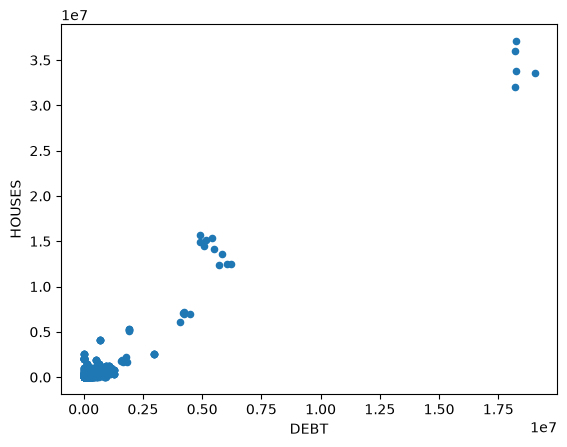

In [45]:
# Create scatter plot of DEBT vs HOUSES for credit-fearful subset
df_fear.plot.scatter(x="DEBT", y="HOUSES");  # x="DEBT", y="HOUSES"

24. assert validasi DataFrame pendidikan (frekuensi 0–1).

In [46]:
# Verify education DataFrame structure
assert "EDUC" in df_educ.columns, "df_educ should have EDUC column"
assert "frequency" in df_educ.columns, "df_educ should have frequency column"
assert df_educ["frequency"].min() >= 0, "Frequencies should be non-negative"
assert df_educ["frequency"].max() <= 1, "Normalized frequencies should be <= 1"
print("All checks passed!")

All checks passed!


Kesimpulan Singkat

- Ukuran kelompok: Sekitar 4.623 dari 28.885 rumah tangga (±16%) termasuk credit fearful, yaitu takut ditolak saat mengajukan kredit.
- Pendapatan: Kelompok fearful terkonsentrasi di pendapatan rendah. Di persentil 0–20, porsinya sekitar 28,8% dibanding 14,0% pada kelompok non-fearful. Di persentil 90–100, porsinya hanya sekitar 4,9% dibanding 29,7%. Pendapatan rendah berkaitan dengan ketakutan terhadap kredit.
- Korelasi: Hubungan ASSET–HOUSES lebih kuat pada kelompok fearful (0,58 vs 0,52). Pada kelompok ini, DEBT dan HOUSES hampir berkorelasi sempurna (≈0,96), artinya utang mereka sebagian besar berupa kredit rumah.
- Usia, ras, dan pendidikan: Ketiganya divisualisasikan untuk membandingkan profil fearful dengan populasi umum. Angka pastinya tidak tampak di output teks, jadi perlu dibaca dari grafik.
- Pendekatan: Notebook ini memperlihatkan alur EDA yang lengkap: memuat data, memfilter, mengganti kode dengan label, membuat grafik, dan menghitung korelasi. Tiap tahap dicek dengan assert.
